In [19]:
import anndata, numpy as np, pandas as pd 
import glob,os 

In [34]:
adata = anndata.read_h5ad(r'/mnt/xuisebnas2/Lab/Bereket_SEA_AD_analysis/SEA_AD_dataset/combined_anndata_object/SEAAD_MTG_MERFISH.2024-12-11.h5ad')
adata

AnnData object with n_obs × n_vars = 1887729 × 180
    obs: 'Donor ID', 'Sex', 'Gender', 'Age at Death', 'Race (choice=White)', 'Race (choice=Black/ African American)', 'Race (choice=Asian)', 'Race (choice=American Indian/ Alaska Native)', 'Race (choice=Native Hawaiian or Pacific Islander)', 'Race (choice=Unknown or unreported)', 'Race (choice=Other)', 'specify other race', 'Hispanic/Latino', 'Highest level of education', 'Years of education', 'PMI', 'Fresh Brain Weight', 'Brain pH', 'Overall AD neuropathological Change', 'Thal', 'Braak', 'CERAD score', 'Overall CAA Score', 'Highest Lewy Body Disease', 'Total Microinfarcts (not observed grossly)', 'Total microinfarcts in screening sections', 'Atherosclerosis', 'Arteriolosclerosis', 'LATE', 'Cognitive Status', 'Last CASI Score', 'Interval from last CASI in months', 'Last MMSE Score', 'Interval from last MMSE in months', 'Last MOCA Score', 'Interval from last MOCA in months', 'APOE4 Status', 'Primary Study Name', 'Secondary Study Name', 

In [21]:
adata.obs.columns

Index(['Donor ID', 'Sex', 'Gender', 'Age at Death', 'Race (choice=White)',
       'Race (choice=Black/ African American)', 'Race (choice=Asian)',
       'Race (choice=American Indian/ Alaska Native)',
       'Race (choice=Native Hawaiian or Pacific Islander)',
       'Race (choice=Unknown or unreported)', 'Race (choice=Other)',
       'specify other race', 'Hispanic/Latino', 'Highest level of education',
       'Years of education', 'PMI', 'Fresh Brain Weight', 'Brain pH',
       'Overall AD neuropathological Change', 'Thal', 'Braak', 'CERAD score',
       'Overall CAA Score', 'Highest Lewy Body Disease',
       'Total Microinfarcts (not observed grossly)',
       'Total microinfarcts in screening sections', 'Atherosclerosis',
       'Arteriolosclerosis', 'LATE', 'Cognitive Status', 'Last CASI Score',
       'Interval from last CASI in months', 'Last MMSE Score',
       'Interval from last MMSE in months', 'Last MOCA Score',
       'Interval from last MOCA in months', 'APOE4 Status',
 

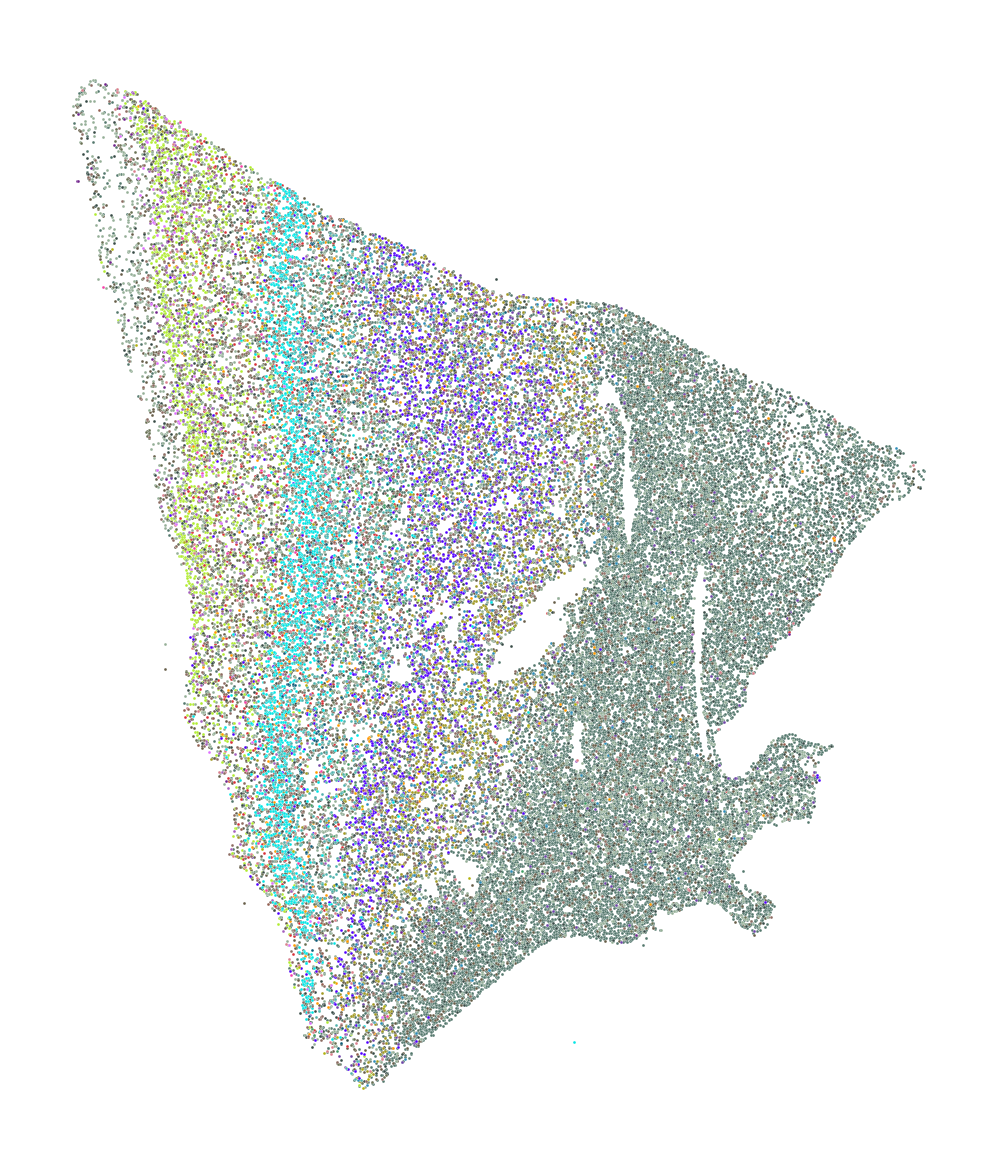

In [23]:
import matplotlib.pyplot as plt 
import seaborn as sns 
color_cmap = dict(zip(adata.obs.Subclass.cat.categories, adata.uns['subclass_colors']))
keep_section = adata.obs['Specimen Barcode'] == '1217500585'
fig, ax = plt.subplots(1,1,dpi = 300)
for celltype_ in adata.obs['Subclass'].unique():
    keep_celltype = adata.obs['Subclass'] == celltype_
    sns.scatterplot(x = adata[keep_section & keep_celltype].obsm['X_spatial_raw'][:,0],
                     y = adata[keep_section & keep_celltype].obsm['X_spatial_raw'][:,1], s = 0.5, c = color_cmap[celltype_])
ax.set_axis_off()
ax.set_aspect('equal')
plt.show()

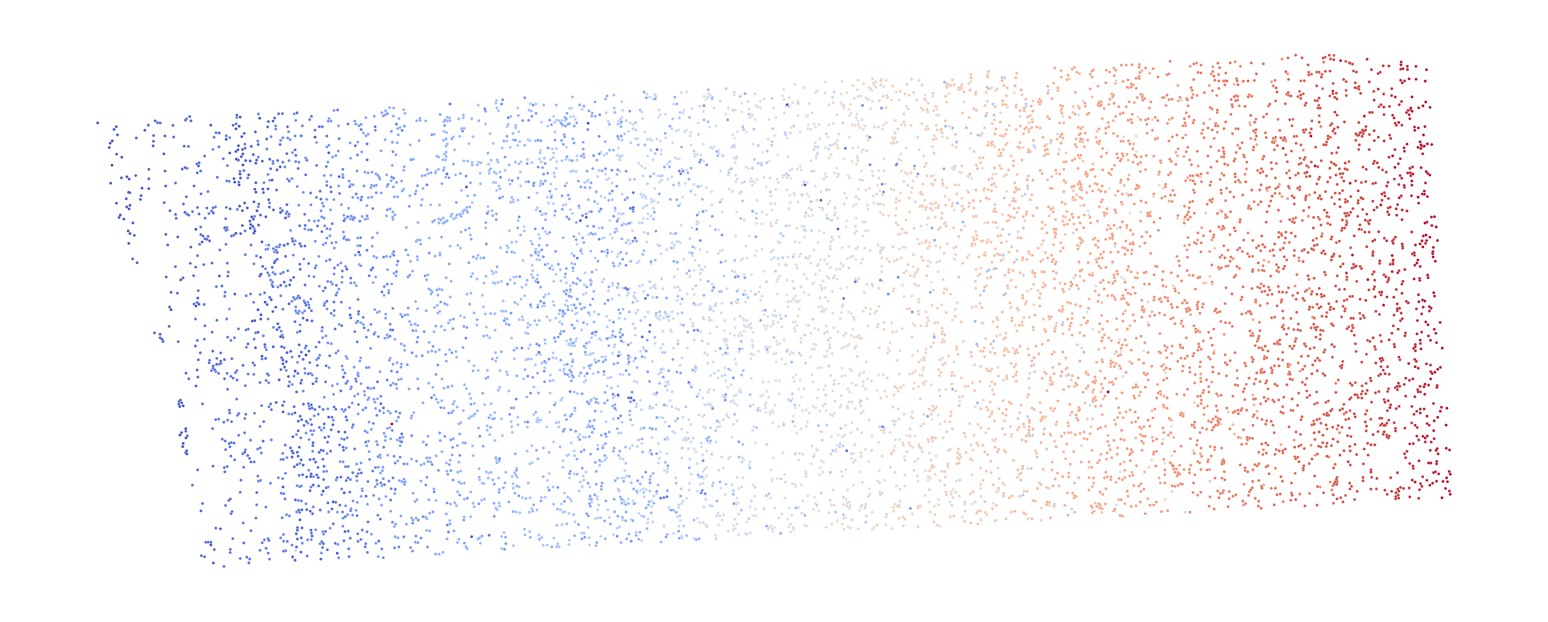

In [ ]:
# cortical depth. 
# cortical depth is provided from only small layer. 
import matplotlib.pyplot as plt 
import seaborn as sns 
color_cmap = dict(zip(adata.obs.Subclass.cat.categories, adata.uns['subclass_colors']))
keep_section = adata.obs['Specimen Barcode'] == '1217500585'
fig, ax = plt.subplots(1,1,dpi = 300)
for celltype_ in adata.obs['Subclass'].unique():
    keep_celltype = adata.obs['Subclass'] == celltype_
    sns.scatterplot(x = adata[keep_section & keep_celltype].obsm['X_spatial_raw'][:,0],
                    y = adata[keep_section & keep_celltype].obsm['X_spatial_raw'][:,1], s = 0.5,
                    c = adata[keep_section & keep_celltype].obs['Normalized depth from pia'], 
                    cmap = 'coolwarm')
ax.set_axis_off()
ax.set_aspect('equal')
plt.show()

In [ ]:
def get_communityComposition(adata,cellType_resolution = 'Group_name',clustering_re = 0.1,radius = 150,n_neighbors = 10):
    # Create a KD tree using the spatial position of cells.
    # then query neighoring cells within specific radius (e.g. radius of 150 um) 

    from scipy.spatial import KDTree
    import numpy as np
    from tqdm import tqdm
    import scanpy as sc 
    import scipy
    from tqdm import tqdm 

    # construct the compostion matrix
    X_spatial = adata.obsm['X_spatial_raw']
    ii =scipy.spatial.KDTree(X_spatial).query_ball_point(X_spatial, r = 200)
    unq_subclass, subclass_idx = np.unique(adata.obs[cellType_resolution], return_inverse=True)
    Mcells = np.zeros((len(adata),len(unq_subclass)))
    for cell_idx,ii_ in tqdm(enumerate(ii), desc = 'adding counts'):
        np.add.at(Mcells[cell_idx], subclass_idx[ii_],1)
    print('constructed compostion matix .......')
    mdata_subset = sc.AnnData(Mcells)
    mdata_subset.obsm['X_spatial_raw'] = X_spatial # akeep track of the spatial information 
    print('Running clustering...')
    sc.pp.neighbors(mdata_subset, n_neighbors=n_neighbors, use_rep='X')
    print('Constructed neighborhood graph...')
    sc.tl.umap(mdata_subset,random_state=0,min_dist=0.1)
    print('done with umap...')
    sc.tl.leiden(mdata_subset,resolution=clustering_re)
    print('done with leiden cluster...')
    cmap = ["#e6194B", "#3cb44b", "#ffe119", "#4363d8", "#f58231", "#911eb4", "#42d4f4", "#f032e6", "#bfef45",
        "#fabed4", "#469990", "#dcbeff", "#9A6324", "#fffac8", "#800000", "#aaffc3", "#808000", "#ffd8b1",
        "#000075", "#a9a9a9"]
    mdata_subset.uns['cmap']=cmap
    return mdata_subset.copy()

In [63]:
subadata = adata[adata.obs['Specimen Barcode'] == '1217500585'].copy()
madata = get_communityComposition(subadata,cellType_resolution = 'Subclass',clustering_re = 0.15,radius = 150,n_neighbors = 15)

adding counts: 61893it [00:00, 89311.16it/s]


In [57]:
madata

AnnData object with n_obs × n_vars = 61893 × 24
    obs: 'leiden'
    uns: 'neighbors', 'umap', 'leiden', 'cmap'
    obsm: 'X_spatial_raw', 'X_umap'
    obsp: 'distances', 'connectivities'

In [58]:
np.unique(madata.obs['leiden'])

array(['0', '1', '10', '2', '3', '4', '5', '6', '7', '8', '9'],
      dtype=object)

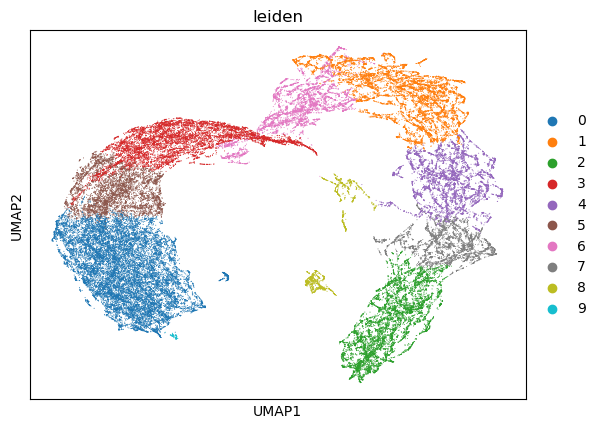

In [64]:
import scanpy as sc 
sc.pl.umap(madata, color = ['leiden'])

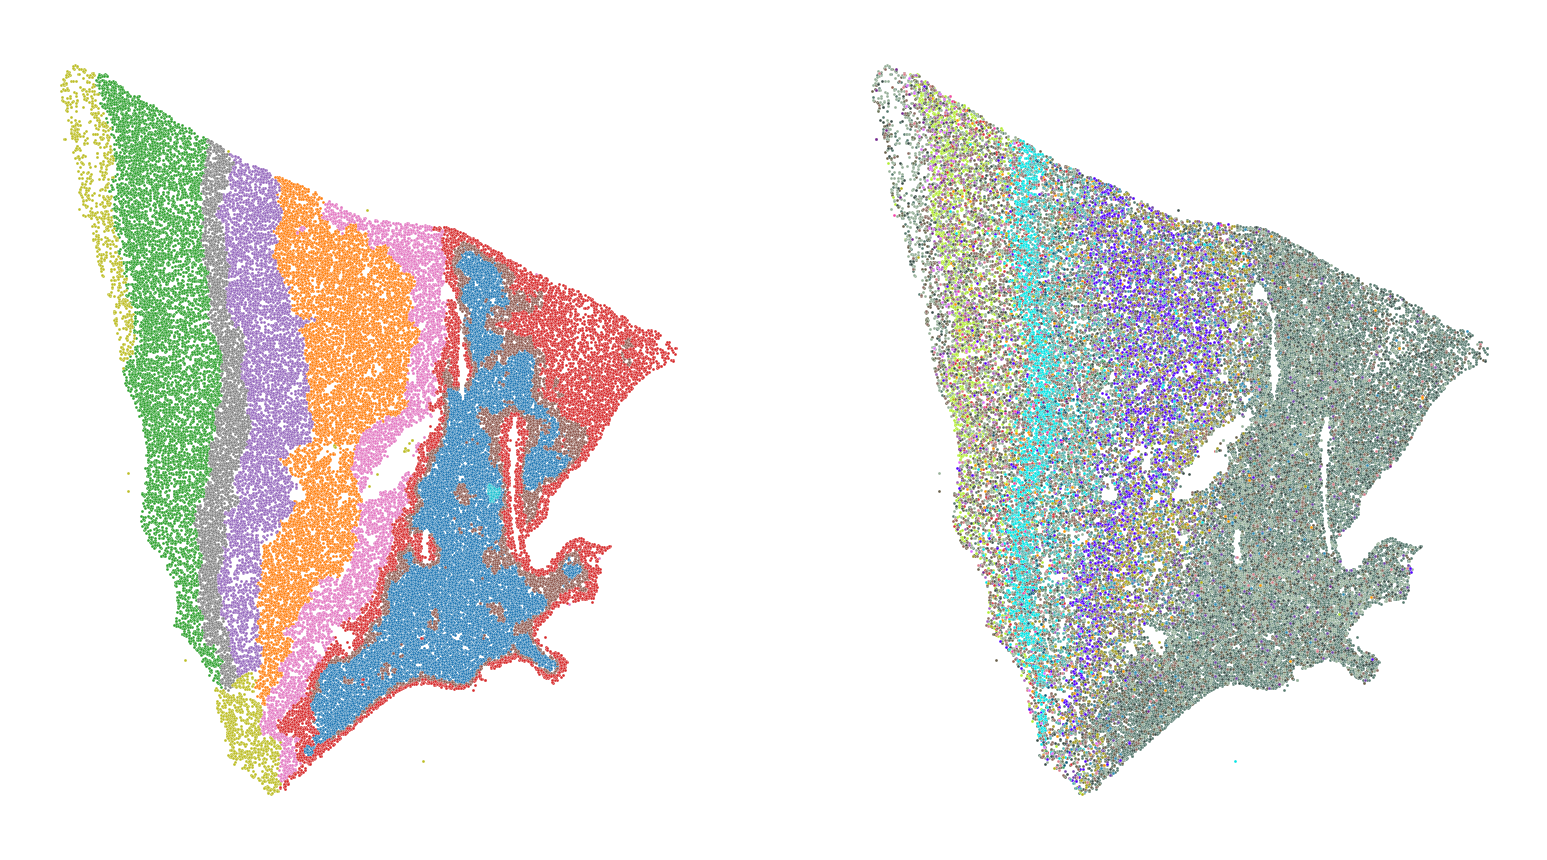

In [69]:
import matplotlib.pyplot as plt 
import seaborn as sns 
color_cmap = dict(zip(madata.obs.leiden.cat.categories, madata.uns['leiden_colors']))
# plot the community modules ++++++++++++++++++
fig, axs = plt.subplots(1,2,dpi = 300)
for ld in madata.obs['leiden'].unique():
    keep_ld = madata.obs['leiden'] == ld
    sns.scatterplot(x = madata[keep_ld].obsm['X_spatial_raw'][:,0],
                     y = madata[keep_ld].obsm['X_spatial_raw'][:,1], s = 0.5, c = color_cmap[ld], ax = axs[0])
axs[0].set_axis_off()
axs[0].set_aspect('equal')
# plot the cell-type spatial map ++++++++++++++ 

color_cmap = dict(zip(adata.obs.Subclass.cat.categories, adata.uns['subclass_colors']))
keep_section = adata.obs['Specimen Barcode'] == '1217500585'
for celltype_ in adata.obs['Subclass'].unique():
    keep_celltype = adata.obs['Subclass'] == celltype_
    sns.scatterplot(x = adata[keep_section & keep_celltype].obsm['X_spatial_raw'][:,0],
                     y = adata[keep_section & keep_celltype].obsm['X_spatial_raw'][:,1], s = 0.5, c = color_cmap[celltype_], ax = axs[1])
axs[1].set_axis_off()
axs[1].set_aspect('equal')
plt.show()

#### Integrated cellular community clustering. 

In [1]:
import anndata, numpy as np, pandas as pd 
import glob,os 

In [2]:
adata = anndata.read_h5ad(r'/mnt/xuisebnas2/Lab/Bereket_SEA_AD_analysis/SEA_AD_dataset/combined_anndata_object/SEAAD_MTG_MERFISH.2024-12-11.h5ad')
adata

AnnData object with n_obs × n_vars = 1887729 × 180
    obs: 'Donor ID', 'Sex', 'Gender', 'Age at Death', 'Race (choice=White)', 'Race (choice=Black/ African American)', 'Race (choice=Asian)', 'Race (choice=American Indian/ Alaska Native)', 'Race (choice=Native Hawaiian or Pacific Islander)', 'Race (choice=Unknown or unreported)', 'Race (choice=Other)', 'specify other race', 'Hispanic/Latino', 'Highest level of education', 'Years of education', 'PMI', 'Fresh Brain Weight', 'Brain pH', 'Overall AD neuropathological Change', 'Thal', 'Braak', 'CERAD score', 'Overall CAA Score', 'Highest Lewy Body Disease', 'Total Microinfarcts (not observed grossly)', 'Total microinfarcts in screening sections', 'Atherosclerosis', 'Arteriolosclerosis', 'LATE', 'Cognitive Status', 'Last CASI Score', 'Interval from last CASI in months', 'Last MMSE Score', 'Interval from last MMSE in months', 'Last MOCA Score', 'Interval from last MOCA in months', 'APOE4 Status', 'Primary Study Name', 'Secondary Study Name', 

In [5]:
def get_GlutCellComposition(adata,sampleID = '',cellType_resolution = 'Group_name',clustering_re = 0.1,radius = 150,n_neighbors = 10):
    # Create a KD tree using the spatial position of cells.
    # then query neighoring cells within specific radius (e.g. radius of 150 um) 
    # use reference cell-type should be excitatory cortical neurons. 

    from scipy.spatial import KDTree
    import numpy as np
    from tqdm import tqdm
    import scanpy as sc 
    import scipy
    from tqdm import tqdm 

    # construct the compostion matrix
    # 1. prepare query(all cells) and reference(glutamtergic neurons) X_spatial 
    X_spatial_query = adata.obsm['X_spatial_raw']
    glut_subclass = list(adata[adata.obs['Class'] == 'Neuronal: Glutamatergic'].obs[cellType_resolution].unique())
    # add oligo and OPC 
    glut_subclass += ['OPC','Oligodendrocyte']
    keep_glut_subclass = adata.obs[cellType_resolution].isin(glut_subclass)
    X_spatial_ref = adata[keep_glut_subclass].obsm['X_spatial_raw']

    ii =scipy.spatial.KDTree(X_spatial_ref).query_ball_point(X_spatial_query, r = radius)
    unq_subclass, subclass_idx = np.unique(adata[keep_glut_subclass].obs[cellType_resolution], return_inverse=True)
    Mcells = np.zeros((len(adata),len(unq_subclass)))
    for cell_idx,ii_ in tqdm(enumerate(ii), desc = 'adding counts'):
        np.add.at(Mcells[cell_idx], subclass_idx[ii_],1)
    print('constructed compostion matix .......')
    mdata_subset = sc.AnnData(Mcells)
    mdata_subset.obsm['X_spatial_raw'] = X_spatial_query # akeep track of the spatial information 
    mdata_subset.obs['sampleID'] = sampleID
    mdata_subset.var_names = unq_subclass
    mdata_subset.obs_names = adata.obs_names
    return mdata_subset.copy()
   

In [6]:
from tqdm import tqdm
compMatrix = []
for sample_ in tqdm(np.unique(adata.obs['Specimen Barcode']), desc = 'compostion matrix across samples'):
    subadata = adata[adata.obs['Specimen Barcode'] == sample_].copy()
    madata = get_GlutCellComposition(subadata,
                                      sampleID = sample_,
                                      cellType_resolution = 'Subclass',
                                      radius = 150)
    compMatrix.append(madata)
compMatrix = anndata.concat(compMatrix, join='outer', merge='same', fill_value=0)

adding counts: 12496it [00:00, 173834.10it/s]    | 0/69 [00:00<?, ?it/s]
compostion matrix across samples:   1%|▏         | 1/69 [00:00<01:01,  1.10it/s]

constructed compostion matix .......


adding counts: 27229it [00:00, 129366.67it/s]
compostion matrix across samples:   3%|▎         | 2/69 [00:01<00:46,  1.45it/s]

constructed compostion matix .......


adding counts: 27977it [00:00, 135514.82it/s]
compostion matrix across samples:   4%|▍         | 3/69 [00:02<00:43,  1.51it/s]

constructed compostion matix .......


... (128 outputs left out)

adding counts: 128300it [00:01, 92961.16it/s]
compostion matrix across samples:  99%|█████████▊| 68/69 [00:36<00:01,  1.60s/it]

constructed compostion matix .......


adding counts: 74740it [00:00, 88747.13it/s]
compostion matrix across samples: 100%|██████████| 69/69 [00:38<00:00,  1.78it/s]


constructed compostion matix .......


In [11]:
compMatrix

AnnData object with n_obs × n_vars = 1887729 × 11
    obs: 'sampleID'
    obsm: 'X_spatial_raw'

- Run the integrated clustering. 

In [ ]:
if False:
    import scanpy as sc 
    # Normalize the data 
    compMatrix.layers['X_raw'] = compMatrix.X.copy()
    total_count = compMatrix.X.sum(axis=-1)
    sc.pp.normalize_total(compMatrix, target_sum = np.median(total_count))
    sc.pp.log1p(compMatrix)
    sc.pp.scale(compMatrix)
    sc.pp.pca(compMatrix)
    sc.pl.pca(compMatrix, color = ['sampleID'])
    # harmony integration 
    sc.external.pp.harmony_integrate(compMatrix, 'sampleID')

In [14]:
# save the harmony integrated adata 
# compMatrix.write_h5ad(r'/mnt/xuisebnas2/Lab/Bereket_SEA_AD_analysis/analysis_result/cellular_comunity_cluster/SEA_AD_compadata.h5ad',compression = 'gzip')
compMatrix = anndata.read_h5ad(r'/mnt/xuisebnas2/Lab/Bereket_SEA_AD_analysis/analysis_result/cellular_comunity_cluster/SEA_AD_compadata.h5ad')

In [15]:
compMatrix.obs.value_counts('sampleID').min()

np.int64(5732)

In [16]:
# downsample the adata object: from each sample, 60% 
import numpy as np
from tqdm import tqdm 
MAX_NUM_CELLS = 5000
rng = np.random.default_rng(seed=42) 
sampleCellID = [rng.choice(df.index.to_numpy(),size = np.minimum(MAX_NUM_CELLS, len(df)), replace=False) for _,df in tqdm(compMatrix.obs.groupby('sampleID'))]
sampleCellID = np.hstack(sampleCellID)
sampleCellID


/tmp/ipykernel_147652/3917552869.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sampleCellID = [rng.choice(df.index.to_numpy(),size = np.minimum(MAX_NUM_CELLS, len(df)), replace=False) for _,df in tqdm(compMatrix.obs.groupby('sampleID'))]
  0%|          | 0/69 [00:00<?, ?it/s]

100%|██████████| 69/69 [00:00<00:00, 1705.71it/s]


array(['1032199', '1028735', '1034230', ..., '444045', '421323', '392805'],
      shape=(345000,), dtype=object)

In [17]:
sub_compMatrix = compMatrix[sampleCellID].copy()
sub_compMatrix

AnnData object with n_obs × n_vars = 345000 × 11
    obs: 'sampleID'
    obsm: 'X_spatial_raw'

In [18]:
%%time
import scanpy as sc, numpy as np, pandas as pd
n_neighbors = 15 
clustering_re = 0.05
print('Running clustering...')
sc.pp.neighbors(sub_compMatrix, n_neighbors=n_neighbors, use_rep='X',)
print('Constructed neighborhood graph...')
sc.tl.umap(sub_compMatrix,random_state=0,min_dist=0.1)
print('done with umap...')
sc.tl.leiden(sub_compMatrix,resolution=clustering_re, flavor='igraph')
print('done with leiden cluster...')
cmap = ["#e6194B", "#3cb44b", "#ffe119", "#4363d8", "#f58231", "#911eb4", "#42d4f4", "#f032e6", "#bfef45",
    "#fabed4", "#469990", "#dcbeff", "#9A6324", "#fffac8", "#800000", "#aaffc3", "#808000", "#ffd8b1",
    "#000075", "#a9a9a9"]
sub_compMatrix.uns['cmap']=cmap

Running clustering...
Constructed neighborhood graph...
done with umap...
done with leiden cluster...
CPU times: user 11h 17min 36s, sys: 14.1 s, total: 11h 17min 50s
Wall time: 14min 3s


In [19]:
sub_compMatrix

AnnData object with n_obs × n_vars = 345000 × 11
    obs: 'sampleID', 'leiden'
    uns: 'neighbors', 'umap', 'leiden', 'cmap'
    obsm: 'X_spatial_raw', 'X_umap'
    obsp: 'distances', 'connectivities'

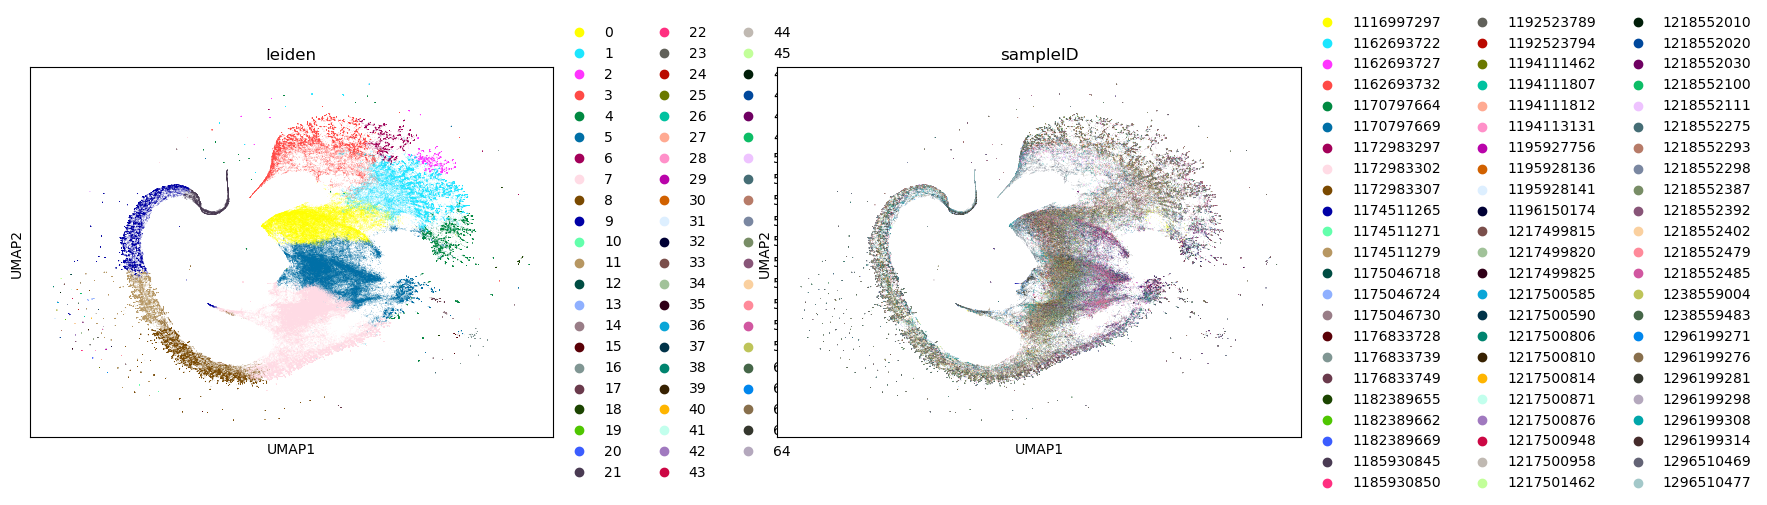

In [20]:
sc.pl.umap(sub_compMatrix, color= ['leiden', 'sampleID'], wspace = 0.3)

In [28]:
sub_compMatrix.obs['sampleID'].unique()[10:20]

['1174511271', '1174511279', '1175046718', '1175046724', '1175046730', '1176833728', '1176833739', '1176833749', '1182389655', '1182389662']
Categories (69, object): ['1116997297', '1162693722', '1162693727', '1162693732', ..., '1296199308', '1296199314', '1296510469', '1296510477']

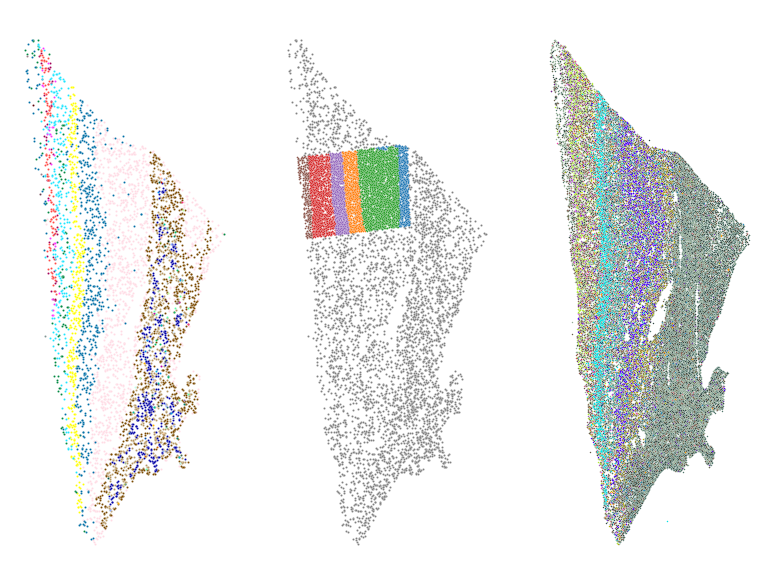

In [47]:
import matplotlib.pyplot as plt 
import seaborn as sns 
sampleID = '1217500585'
color_cmap = dict(zip(sub_compMatrix.obs.leiden.cat.categories, sub_compMatrix.uns['leiden_colors']))
# plot the community modules ++++++++++++++++++
fig, axs = plt.subplots(1,3,dpi = 150)
for ld in sub_compMatrix.obs['leiden'].unique():
    keep_ld = (sub_compMatrix.obs['leiden'] == ld) & (sub_compMatrix.obs['sampleID'] == sampleID )
    sns.scatterplot(x = sub_compMatrix[keep_ld].obsm['X_spatial_raw'][:,0],
                     y = sub_compMatrix[keep_ld].obsm['X_spatial_raw'][:,1], s = 1, c = color_cmap[ld], ax = axs[0])
axs[0].set_axis_off()
# axs[0].set_aspect('equal')
# plot the cell-type spatial map ++++++++++++++ 
keep_sample = sub_compMatrix.obs['sampleID'] == sampleID 
sns.scatterplot(x = sub_compMatrix[keep_sample].obsm['X_spatial_raw'][:,0],
                     y = sub_compMatrix[keep_sample].obsm['X_spatial_raw'][:,1], s = 1, c = 'gray', ax = axs[1])

for  layer_annot in set(adata.obs['Layer annotation']):
    keep_sample = (adata.obs['Layer annotation'] == layer_annot)  & (adata.obs['Specimen Barcode'] == sampleID)
    sns.scatterplot(x = adata[keep_sample].obsm['X_spatial_raw'][:,0],
                     y = adata[keep_sample].obsm['X_spatial_raw'][:,1], s = 0.7, ax = axs[1])
    
axs[1].set_axis_off()

color_cmap = dict(zip(adata.obs.Subclass.cat.categories, adata.uns['subclass_colors']))
keep_section = adata.obs['Specimen Barcode'] == sampleID
for celltype_ in adata.obs['Subclass'].unique():
    keep_celltype = adata.obs['Subclass'] == celltype_
    sns.scatterplot(x = adata[keep_section & keep_celltype].obsm['X_spatial_raw'][:,0],
                    y = adata[keep_section & keep_celltype].obsm['X_spatial_raw'][:,1], s = 0.5, c = color_cmap[celltype_], ax = axs[2])
axs[2].set_axis_off()
# axs[2].set_aspect('equal')
plt.show()

#### GMM classifier: transfer the cortical layer annotation to every cell in each section
- Ground truth: `adata.obs['Layer annotation']`, available only for the cells inside each section's annotated strip (4–63% of cells per section). The empty-string label (normalized depth ≈ 0.93–1, mostly oligodendrocytes) becomes `WM`.
- Features: the composition matrix `compMatrix.X` (glutamatergic + Oligo/OPC counts within 150 µm).
- Fit one Gaussian mixture per layer for p(x | layer), with the number of components chosen by BIC, then assign layers to the unannotated cells with Bayes' rule.
- Validation holds out **whole sections**: neighboring cells have near-identical features, so a random split would overestimate accuracy.
- Cells that fit no layer's GMM well (out of distribution) or are ambiguous can be set to `unassigned`.
- Implementation: `gmm_classifier.py`

##### GMM classifer. 

In [48]:
compMatrix

AnnData object with n_obs × n_vars = 1887729 × 11
    obs: 'sampleID'
    obsm: 'X_spatial_raw'

annotated cells: 368,795 / 1,887,729
layer_gt
L2/3    120356
L6       90825
L5       59644
L4       59302
WM       27200
L1       11468
Name: count, dtype: int64
components per layer (BIC): {'L1': 6, 'L2/3': 6, 'L4': 6, 'L5': 6, 'L6': 6, 'WM': 6}
held-out sections: 14 | accuracy = 0.823 | balanced accuracy = 0.794
              precision    recall  f1-score   support

          L1      0.528     0.720     0.609      2593
        L2/3      0.916     0.912     0.914     23842
          L4      0.811     0.857     0.833     11593
          L5      0.887     0.694     0.779     12478
          L6      0.839     0.801     0.819     18394
          WM      0.562     0.779     0.653      5345

    accuracy                          0.823     74245
   macro avg      0.757     0.794     0.768     74245
weighted avg      0.837     0.823     0.826     74245



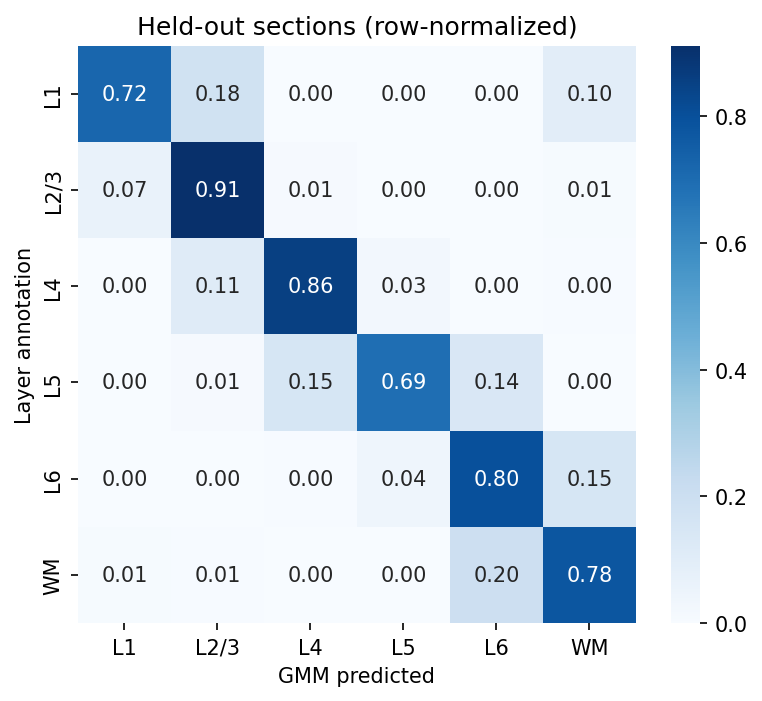

CPU times: user 18min 7s, sys: 7.01 s, total: 18min 14s
Wall time: 23.3 s


In [49]:
%%time
# 1. Layer labels + leave-sections-out validation
import numpy as np, pandas as pd, scipy.sparse as sp
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, classification_report
from gmm_classifier import GMMClassifier

LAYER_ORDER = ['L1', 'L2/3', 'L4', 'L5', 'L6', 'WM']

def get_features(ad, use_rep='X'):
    X = ad.X if use_rep == 'X' else ad.obsm[use_rep]
    return np.asarray(X.toarray() if sp.issparse(X) else X, dtype=np.float64)

def cap_per_class(y, max_n, seed=0):
    rng = np.random.default_rng(seed)
    return np.hstack([rng.choice(np.where(y == c)[0], size=min(max_n, (y == c).sum()), replace=False) for c in np.unique(y)])

# ground-truth layer per cell (compMatrix obs_names == adata obs_names); '' -> 'WM', NaN -> not annotated
layer = adata.obs['Layer annotation'].reindex(compMatrix.obs_names).astype(object)
layer = layer.where(layer.isna() | (layer.astype(str).str.strip() != ''), 'WM')
compMatrix.obs['layer_gt'] = pd.Categorical(layer, categories=LAYER_ORDER)
annotated = compMatrix.obs['layer_gt'].notna().to_numpy()
print(f'annotated cells: {annotated.sum():,} / {len(annotated):,}')
print(compMatrix.obs['layer_gt'].value_counts())

USE_REP = 'X'
MAX_TRAIN_PER_CLASS = 20000      # cap per layer so the BIC search stays fast
GMM_PARAMS = dict(n_components='bic', component_range=range(1, 7), covariance_type='full', reg_covar=1e-3)

X_all = get_features(compMatrix, USE_REP)
X_lab = X_all[annotated]
y_lab = compMatrix.obs['layer_gt'].astype(str).to_numpy()[annotated]
g_lab = compMatrix.obs['sampleID'].astype(str).to_numpy()[annotated]
# priors = layer frequencies in the annotated strips (the per-class cap would otherwise distort them)
layer_priors = pd.Series(y_lab).value_counts(normalize=True).to_dict()

# hold out 20% of SECTIONS
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0).split(X_lab, y_lab, groups=g_lab))
keep = tr[cap_per_class(y_lab[tr], MAX_TRAIN_PER_CLASS)]
gmm_clf = GMMClassifier(priors=layer_priors, **GMM_PARAMS).fit(X_lab[keep], y_lab[keep])
print('components per layer (BIC):', dict(zip(gmm_clf.classes_, gmm_clf.n_components_)))

y_pred = gmm_clf.predict(X_lab[te])
print(f'held-out sections: {len(np.unique(g_lab[te]))} | accuracy = {accuracy_score(y_lab[te], y_pred):.3f} '
      f'| balanced accuracy = {balanced_accuracy_score(y_lab[te], y_pred):.3f}')
print(classification_report(y_lab[te], y_pred, labels=LAYER_ORDER, digits=3))

cm = confusion_matrix(y_lab[te], y_pred, labels=LAYER_ORDER, normalize='true')
fig, ax = plt.subplots(figsize=(6, 5), dpi=150)
sns.heatmap(pd.DataFrame(cm, index=LAYER_ORDER, columns=LAYER_ORDER), annot=True, fmt='.2f', cmap='Blues', ax=ax)
ax.set_xlabel('GMM predicted'); ax.set_ylabel('Layer annotation'); ax.set_title('Held-out sections (row-normalized)')
plt.show()

In [50]:
%%time
# 2. Refit on all annotated cells, then assign a layer to every cell
MIN_PROBA = None          # e.g. 0.6 -> cells ambiguous between layers become 'unassigned'
NOVELTY_QUANTILE = 0.01   # cells less likely under every layer GMM than 99% of annotated cells -> 'unassigned'; None to disable

keep = cap_per_class(y_lab, MAX_TRAIN_PER_CLASS)
gmm_clf = GMMClassifier(priors=layer_priors, **GMM_PARAMS).fit(X_lab[keep], y_lab[keep])
min_loglik = gmm_clf.loglik_threshold(X_lab, NOVELTY_QUANTILE) if NOVELTY_QUANTILE else None

labels, conf, loglik = gmm_clf.predict_with_confidence(X_all, min_proba=MIN_PROBA, min_loglik=min_loglik)
compMatrix.obs['layer_gmm'] = pd.Categorical(labels.astype(str), categories=LAYER_ORDER + ['unassigned'])
compMatrix.obs['layer_gmm_proba'] = conf
compMatrix.obs['layer_gmm_loglik'] = loglik
# final layer: keep the ground truth where annotated, GMM prediction elsewhere
layer_final = compMatrix.obs['layer_gt'].astype(object).where(annotated, compMatrix.obs['layer_gmm'].astype(object))
compMatrix.obs['layer_final'] = pd.Categorical(layer_final, categories=LAYER_ORDER + ['unassigned'])

print(f'resubstitution agreement on annotated cells: {(labels[annotated] == y_lab).mean():.3f}')
print('predicted layers on UNannotated cells:')
print(compMatrix.obs.loc[~annotated, 'layer_gmm'].value_counts(normalize=True).round(3))

resubstitution agreement on annotated cells: 0.835
predicted layers on UNannotated cells:
layer_gmm
WM            0.370
L2/3          0.240
L4            0.121
L6            0.119
L5            0.082
unassigned    0.034
L1            0.033
Name: proportion, dtype: float64
CPU times: user 30min 39s, sys: 11 s, total: 30min 50s
Wall time: 29.4 s


In [56]:
np.unique(compMatrix.obs['sampleID'])[20:30]

array(['1182389669', '1185930845', '1185930850', '1192523789',
       '1192523794', '1194111462', '1194111807', '1194111812',
       '1194113131', '1195927756'], dtype=object)

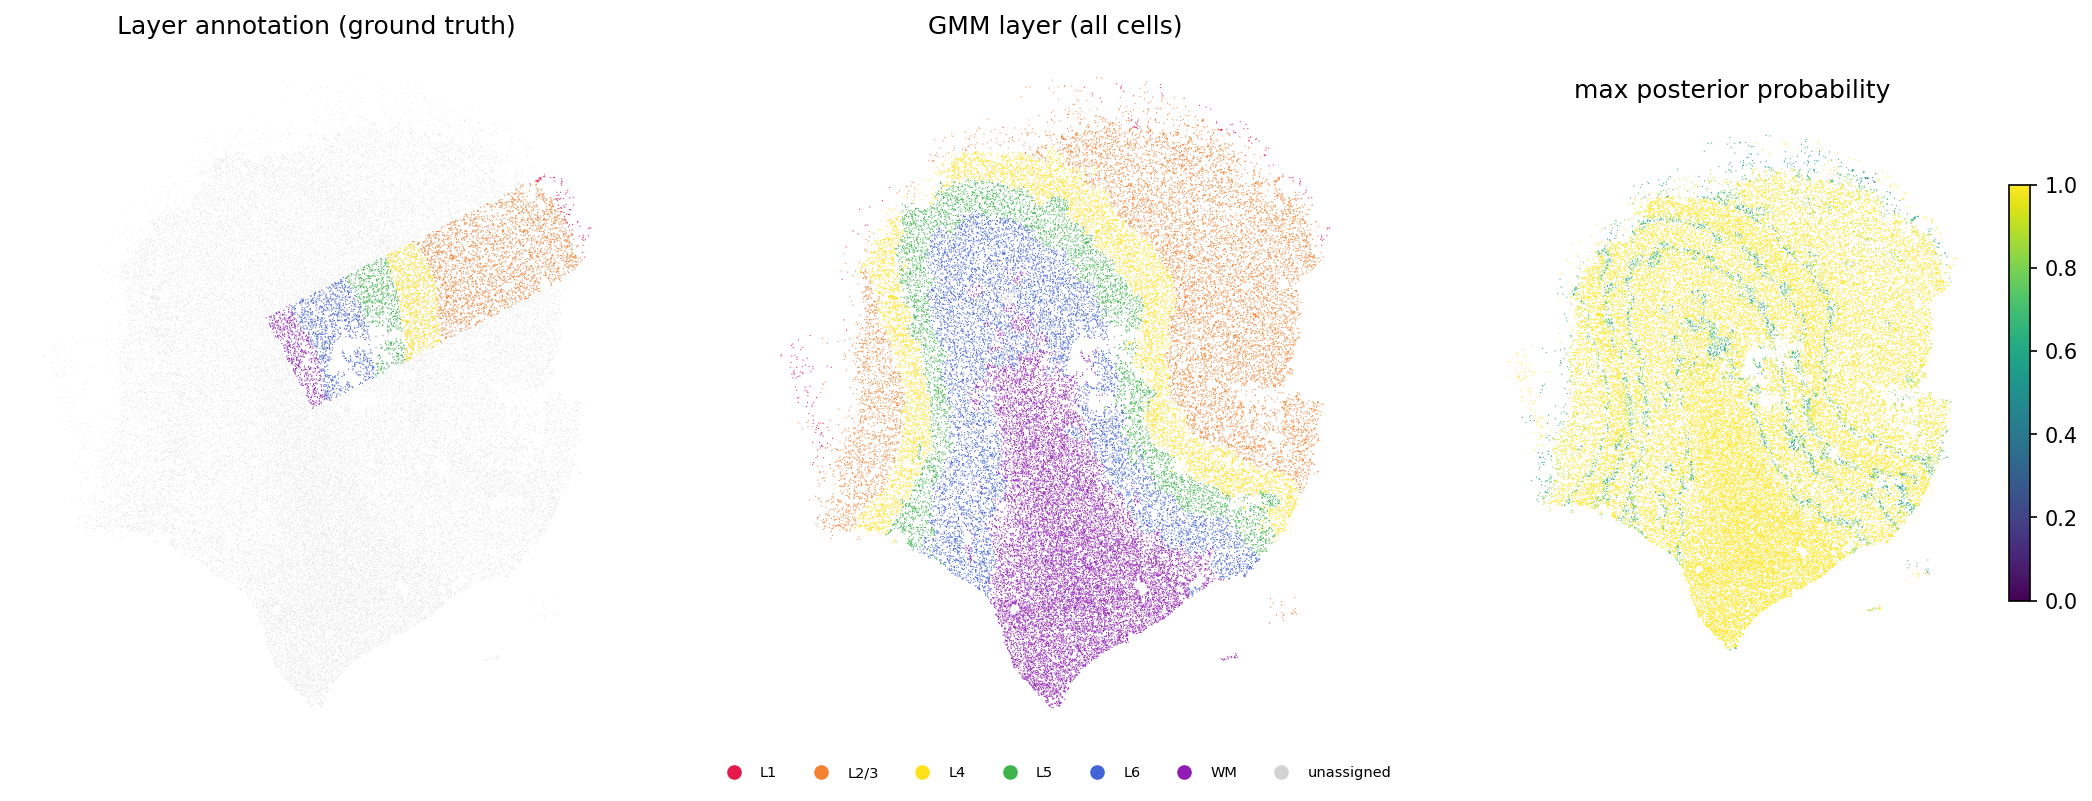

In [57]:
# 3. Spatial check for one section: annotated strip | GMM layers for all cells | confidence
sampleID = '1194111807'#'1217500585'
layer_cmap = {'L1': '#e6194B', 'L2/3': '#f58231', 'L4': '#ffe119', 'L5': '#3cb44b', 'L6': '#4363d8',
              'WM': '#911eb4', 'unassigned': '#d3d3d3'}

sec = compMatrix[compMatrix.obs['sampleID'] == sampleID]
xy = sec.obsm['X_spatial_raw']
gt = sec.obs['layer_gt'].astype(object)
has_gt = gt.notna().to_numpy()
fig, axs = plt.subplots(1, 3, figsize=(18, 6), dpi=150)
axs[0].scatter(xy[:, 0], xy[:, 1], s=0.3, c='#eeeeee', linewidths=0)
axs[0].scatter(xy[has_gt, 0], xy[has_gt, 1], s=0.3, c=gt[has_gt].map(layer_cmap).to_numpy(), linewidths=0)
axs[0].set_title('Layer annotation (ground truth)')
axs[1].scatter(xy[:, 0], xy[:, 1], s=0.3, c=sec.obs['layer_gmm'].astype(str).map(layer_cmap).to_numpy(), linewidths=0)
axs[1].set_title('GMM layer (all cells)')
im = axs[2].scatter(xy[:, 0], xy[:, 1], s=0.3, c=sec.obs['layer_gmm_proba'], cmap='viridis', vmin=0, vmax=1, linewidths=0)
axs[2].set_title('max posterior probability')
fig.colorbar(im, ax=axs[2], shrink=0.6)
for ax in axs:
    ax.set_axis_off(); ax.set_aspect('equal')
handles = [plt.Line2D([], [], marker='o', ls='', color=v, label=k) for k, v in layer_cmap.items()]
axs[1].legend(handles=handles, bbox_to_anchor=(0.5, -0.02), loc='upper center', ncol=7, frameon=False, fontsize=7)
plt.show()

In [59]:
compMatrix.obs

,sampleID,layer_gt,layer_gmm,layer_gmm_proba,layer_gmm_loglik,layer_final
1024919,1116997297,NaN,L2/3,0.947300,0.558068,L2/3
1025556,1116997297,NaN,WM,1.000000,-8.404013,WM
1033124,1116997297,WM,L6,0.999258,-11.763961,WM
1030394,1116997297,NaN,L2/3,0.996548,7.376437,L2/3
1031515,1116997297,NaN,L5,0.989663,-19.625437,L5
...,...,...,...,...,...,...
420287,1296510477,NaN,WM,0.999877,-26.731084,WM
382636,1296510477,NaN,L6,0.999701,-24.321929,L6
422047,1296510477,NaN,WM,1.000000,-13.776961,WM
402496,1296510477,L2/3,L2/3,1.000000,-7.831204,L2/3


In [61]:
# save the adata.obs 
compMatrix.obs.to_csv(r'/mnt/xuisebnas2/Lab/Bereket_SEA_AD_analysis/analysis_result/cellular_comunity_cluster/GMM_based_layerAnnot.csv')